# Business Understanding

The Business Understanding phase defines the main objective of the problem, the relevant requirements and the criteria used to determine whether the proposed solution is useful and aligned with the goals of Question 1.

## Analysis of Requirements with the End User

The main objective of Question 1 is to predict the final ranking of the teams for a given season.

For the prediction to be useful, the following requirements were identified:

- the prediction must be made before the start of the target season
- only information available from previous seasons and relevant to the problem can be used
- the competitive structure of the league must be respected, particularly the ranking within divisions
- the model must produce results that can be directly compared with the real ranking
- the methodology should work across different seasons and not only for a single year
- the performance should be compared with a simple reference strategy in order to verify whether the model adds predictive value

In addition to the main objective, there are other relevant factors to consider. The structure of the NHL changed over time, including the number of games played, the number of teams and the organization of divisions, and there is also missing information in some older seasons. For this reason, historical data cannot be treated as if all seasons were directly equivalent.

It is also important to consider that the main objective is not to predict the exact number of points achieved by each team, but to obtain a final ordering that is as close as possible to the real ranking. Therefore, the evaluation should give particular importance to ranking error.

The main success criterion is therefore to achieve a low Mean Rank Error and to demonstrate that the model performs consistently across several historical seasons.

The requirements were identified from the project statement and from the practical constraints of the prediction problem, especially the need to make the prediction before the target season starts and to use only information that would be available at that time.

## Business Goal

The business goal is to predict the final regular-season ranking of the teams before the target season starts, using only information that would be available at that time.

The prediction should be as close as possible to the real final ranking and should work consistently across different seasons.

## Translation of Business Goals into Data Mining Goals

The business goal is translated into a supervised regression problem.

The model predicts the expected performance of each team using historical data from previous seasons. These predictions are then used to rank the teams within their divisions.

The Mean Rank Error is used as the main evaluation metric because it directly measures how close the predicted ranking is to the real ranking.

# Data exploration

Exploration in the data so we can better understand the dataset. Also used to create the dataset to train models do answer Q1.

### Load the data and first cleaning

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def read_and_clean(path):
    df = pd.read_csv(path, dtype=str, skipinitialspace=True)
    df.columns = df.columns.str.strip()
    for c in df.columns:
        df[c] = df[c].str.strip()
    return df.replace("", np.nan)

#first clean the data
df_teams = read_and_clean("../hockey_development_data/Teams.csv").query("lgID == 'NHL'").astype({'year': int})
df_scoring = read_and_clean("../hockey_development_data/Scoring.csv").query("lgID == 'NHL'").astype({'year': int})
df_goalies = read_and_clean("../hockey_development_data/Goalies.csv").query("lgID == 'NHL'").astype({'year': int})
df_coaches = read_and_clean("../hockey_development_data/Coaches.csv").query("lgID == 'NHL'").astype({'year': int})

## Data Understanding 
Apply some methods so we can understand the distribution and relation in the data

In [57]:
from scipy.stats import spearmanr, kruskal

sns.set_theme(style="whitegrid")

# convert tu num
num_cols = ['G', 'W', 'L', 'Pts', 'GF', 'GA', 'rank', 'year']
for col in num_cols:
    df_teams[f'{col}_num'] = pd.to_numeric(df_teams[col], errors='coerce')

#normalized metrics
df_teams['Pts_per_G'] = df_teams['Pts_num'] / df_teams['G_num']
df_teams['GF_per_G'] = df_teams['GF_num'] / df_teams['G_num']
df_teams['GA_per_G'] = df_teams['GA_num'] / df_teams['G_num']
df_teams['Goal_Diff_per_G'] = df_teams['GF_per_G'] - df_teams['GA_per_G']
df_teams['decade'] = (df_teams['year_num'] // 10) * 10

df_teams['Playoff_Tier'] = np.where(
    df_teams['playoff'].isna(), 'Missed Playoffs',
    np.where(df_teams['playoff'] == 'SC', 'Stanley Cup Winner', 'Playoff Qualifier')
)

print("Descriptive Statistics (Raw vs Per Game Normalized):")
display(df_teams[['GF_num', 'GA_num', 'Pts_num', 'GF_per_G', 'GA_per_G', 'Pts_per_G', 'Goal_Diff_per_G']].describe().round(2))

print("\n3D Pivot Table: Average Points per Game (Pts/G) by Decade and Playoff Tier:")
pivot_3d = df_teams.pivot_table(
    values = 'Pts_per_G', 
    index = 'decade', 
    columns = 'Playoff_Tier', 
    aggfunc = 'mean'
)[['Missed Playoffs', 'Playoff Qualifier', 'Stanley Cup Winner']]
display(pivot_3d.round(3))

# Kruskal-Wallis and Spearman Correlation
groups = [group['Goal_Diff_per_G'].dropna().values for _, group in df_teams.groupby('Playoff_Tier')]
kw_stat, kw_pval = kruskal(*groups)
rho, sp_pval = spearmanr(df_teams['Goal_Diff_per_G'], df_teams['rank_num'], nan_policy='omit')

print(f"\nStatistical Tests:")
print(f"- Kruskal-Wallis Test (Goal Diff/G across Playoff Tiers): H = {kw_stat:.2f}, p-value = {kw_pval:.2e}")
print(f"- Spearman Rank Correlation (Goal Diff/G vs Division Rank): rho = {rho:.3f}, p-value = {sp_pval:.2e}")

Descriptive Statistics (Raw vs Per Game Normalized):


,GF_num,GA_num,Pts_num,GF_per_G,GA_per_G,Pts_per_G,Goal_Diff_per_G
count,1265.00,1265.00,1265.00,1265.00,1265.00,1265.00,1265.00
mean,226.75,226.75,74.51,3.09,3.09,1.02,-0.00
std,70.58,72.53,23.05,0.67,0.72,0.23,0.76
min,17.00,35.00,2.00,0.75,0.98,0.26,-3.58
25%,189.00,184.00,58.00,2.62,2.57,0.86,-0.44
50%,231.00,232.00,77.00,3.00,3.01,1.04,0.02
75%,277.00,278.00,92.00,3.52,3.54,1.18,0.46
max,446.00,446.00,132.00,5.58,7.38,1.75,2.70



3D Pivot Table: Average Points per Game (Pts/G) by Decade and Playoff Tier:


Playoff_Tier,Missed Playoffs,Playoff Qualifier,Stanley Cup Winner
decade,,,
1910,0.687,1.209,1.383
1920,0.759,1.195,1.201
1930,0.746,1.081,1.180
1940,0.743,1.065,1.241
1950,0.761,1.057,1.306
1960,0.776,1.090,1.204
1970,0.724,1.128,1.458
1980,0.744,1.064,1.314
1990,0.804,1.115,1.214



Statistical Tests:
- Kruskal-Wallis Test (Goal Diff/G across Playoff Tiers): H = 656.09, p-value = 3.40e-143
- Spearman Rank Correlation (Goal Diff/G vs Division Rank): rho = -0.794, p-value = 8.90e-275


### Statistical Methods Complexity

The statistical analysis combines 1D/2D descriptive statistics, a 3D multivariate pivot table across decades and playoff tiers, and non parametric hypothesis tests. 

**Justification of Methods:**
- **Descriptive Statistics & 3D Pivot Table:** Selected to compare raw totals against per game ratios and to observe how the threshold for postseason success evolved across historical decades.

- **Kruskal-Wallis Test:** Chosen because historical sports metrics contain extreme era anomalies (outliers) and do not follow normal distributions across unbalanced playoff tiers.

- **Spearman Rank Correlation:** Chosen over Pearson correlation because division rank (rank_num) is an ordinal, discrete variable rather than a continuous one, requiring a rank based association measure.

### Interpretation of Statistical Results

The Kruskal-Wallis result indicates that goal differential per game differs significantly between playoff performance groups.

The Spearman correlation shows a strong negative association between goal differential per game and division rank, meaning that teams with a better goal differential tend to achieve better ranking positions.

### Statistical Findings & Domain Knowledge Extraction

1. **Raw Totals vs. Per-Game Normalization:** The descriptive table shows a massive standard deviation in raw points (std = 23.05, ranging from 2 to 132) and goals (17 to 446) because the NHL schedule expanded from 18 to 24 games in the 1910s to 82+ games in the modern era. Normalizing by games played (Pts_per_G, GF_per_G) stabilizes the distribution, proving that raw totals cannot be used directly in longitudinal predictive models.

2. **3D Decade × Playoff Tier Analysis:** Across all decades, Stanley Cup Winners consistently average between 1.180 and 1.458 Pts/G, Playoff Qualifiers average 1.057 to 1.216 Pts/G, and teams that Missed Playoffs fall to 0.687 to 0.933 Pts/G. In the 1920s, Stanley Cup winners had regular-season averages very close to other qualifiers, showing that historical playoff formats allowed lower seeded teams to peak in the postseason.

3. **Non-Parametric Significance Tests:** The Kruskal-Wallis test confirms a statistically significant difference in goal differential per game across the three playoff tiers ($H = 656.09$, $p = 3.40 \times 10^{-143}$), and Spearman's rank correlation ($\rho = -0.794$, $p = 8.90 \times 10^{-275}$) confirms a strong negative monotonic relationship between goal differential per game and division ranking (rank = 1 is best).

/var/folders/ty/4m9zd4tj4nd7bct95q84x74c0000gn/T/ipykernel_26700/3052699672.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


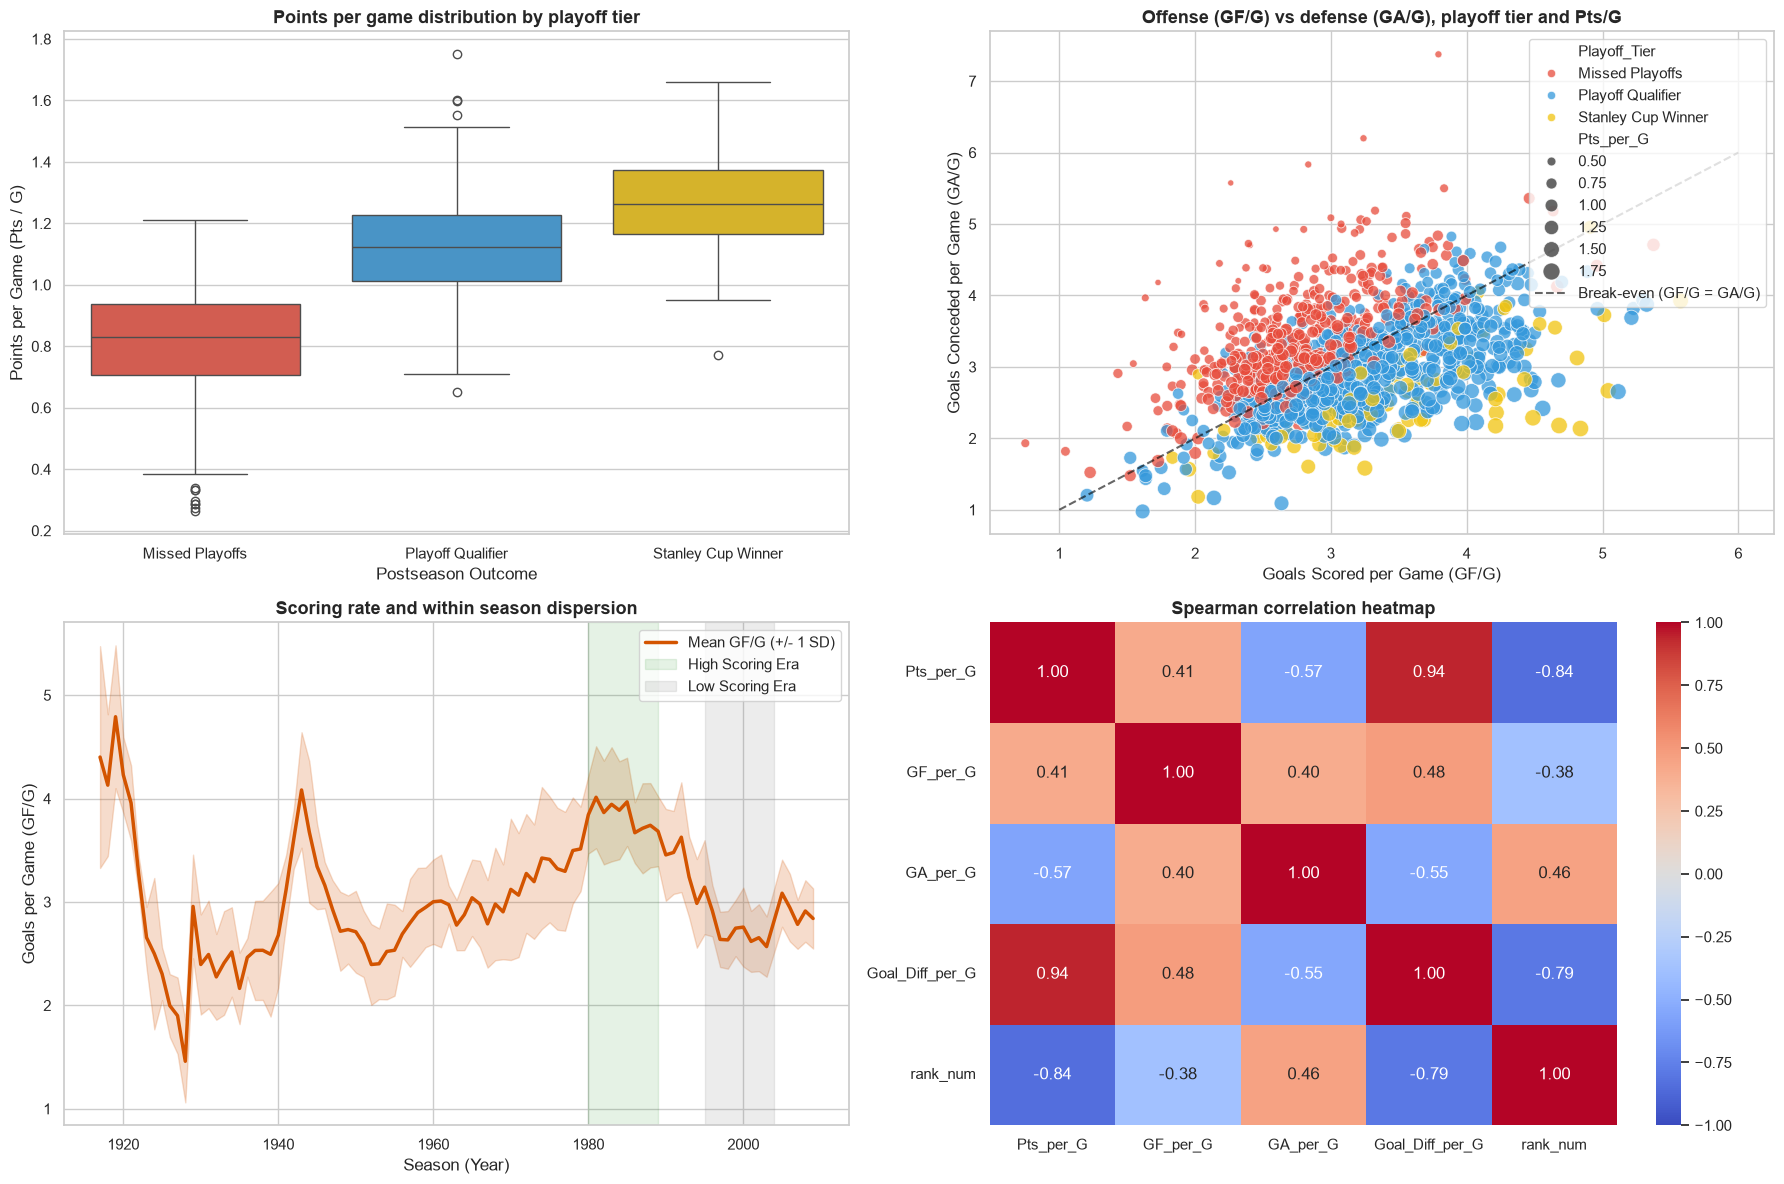

In [58]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Points per game by playoff tier (2D)
sns.boxplot(
    data = df_teams, x='Playoff_Tier', y='Pts_per_G', 
    order = ['Missed Playoffs', 'Playoff Qualifier', 'Stanley Cup Winner'],
    palette = ['#e74c3c', '#3498db', '#f1c40f'], ax=axes[0, 0]
)
axes[0, 0].set_title('Points per game distribution by playoff tier', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Postseason Outcome')
axes[0, 0].set_ylabel('Points per Game (Pts / G)')

#GF/G vs GA/G + Playoff Tier (Color) + Points/G (Size) (4D)
sns.scatterplot(
    data = df_teams, x='GF_per_G', y='GA_per_G', 
    hue = 'Playoff_Tier', size='Pts_per_G', sizes=(20, 150),
    hue_order = ['Missed Playoffs', 'Playoff Qualifier', 'Stanley Cup Winner'],
    palette = ['#e74c3c', '#3498db', '#f1c40f'], alpha=0.75, ax=axes[0, 1]
)
#GF/G == GA/G
axes[0, 1].plot([1, 6], [1, 6], ls='--', color='black', alpha=0.6, label='Break-even (GF/G = GA/G)')
axes[0, 1].set_title('Offense (GF/G) vs defense (GA/G), playoff tier and Pts/G', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Goals Scored per Game (GF/G)')
axes[0, 1].set_ylabel('Goals Conceded per Game (GA/G)')
axes[0, 1].legend(loc='upper right', frameon=True)

# 3D Time-Series about evolution of goals per game across NHL eras
sns.lineplot(
    data=df_teams, x='year_num', y='GF_per_G', 
    errorbar='sd', color='#d35400', lw=2.5, 
    label='Mean GF/G (+/- 1 SD)', ax=axes[1, 0]  
)
axes[1, 0].axvspan(1980, 1989, color='green', alpha=0.1, label='High Scoring Era')
axes[1, 0].axvspan(1995, 2004, color='gray', alpha=0.15, label='Low Scoring Era')
axes[1, 0].set_title('Scoring rate and within season dispersion', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Season (Year)')
axes[1, 0].set_ylabel('Goals per Game (GF/G)')
axes[1, 0].legend(loc='upper right')

#Heatmap: correlation matrix of normalized team metrics
corr_cols = ['Pts_per_G', 'GF_per_G', 'GA_per_G', 'Goal_Diff_per_G', 'rank_num']
corr_matrix = df_teams[corr_cols].corr(method='spearman')
sns.heatmap(
    corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1, 1]
)
axes[1, 1].set_title('Spearman correlation heatmap', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

### Visual Interpretation & Knowledge Extraction

1. **Plot 1 - Target Variable Justification (Boxplot):** The distribution of Pts_per_G shows a clear separation between teams that missed the playoffs (median ~0.80), playoff qualifiers (median ~1.10), and Stanley Cup winners (median ~1.30), with minimal interquartile overlap between non playoff and playoff teams. This visually validates Pts_per_G as the continuous regression target to rank teams.

2. **Plot 2 - Offensive vs. Defensive Balance (3D Scatterplot):** Mapping GF_per_G against GA_per_G across playoff tiers reveals that almost all Stanley Cup winners (yellow) and most playoff qualifiers (blue) sit below the **GF/G = GA/G** line (positive goal differential), whereas teams above the line (conceding more than they score) overwhelmingly miss the playoffs (red).

3. **Plot 3 - Historical Era Shifts & Data Preparation Need (Time-Series):** The scoring rate fluctuates substantially across NHL history, peaking during the **High Scoring Era** (~3.8–4.0 GF/G) and dropping sharply during the defensive **Low Score Era** (~2.6–2.8 GF/G), while within-season dispersion ($\pm 1$ SD band) also narrows in modern eras. This proves that per game ratios alone are not comparable across eras, directly justifying **within season Z-score standardization** in Data Preparation.

4. **Plot 4 - Multicollinearity Detection (Spearman Heatmap):** Pts_per_G and Goal_Diff_per_G exhibit near perfect positive correlation ($\rho = 0.96$), while both show strong negative correlation with rank_num ($\rho = -0.81$ and $\rho = -0.79$). Including both in linear or distance-based models would introduce severe multicollinearity, justifying a **correlation filter ($|r| > 0.85$)** during Feature Selection.

### Data Quality Tests 
Before processing the data, we test for null values, duplicates, logical rules of hockey, e.g., the number of wins cannot exceed the number of games played, and the range of years covered.

In [59]:
print("Nulls")
print(df_teams[['G', 'W', 'L', 'Pts']].isna().sum())

print(f"\nDuplicates")
print(f"Dup lines in table Teams: {df_teams.duplicated().sum()}")

# Consistency and Validity
df_teams[['G', 'W', 'L']] = df_teams[['G', 'W', 'L']].apply(pd.to_numeric, errors='coerce')
invalid_games = df_teams[df_teams['G'] < (df_teams['W'] + df_teams['L'])]
print(f"\nConsistency and Validity")
print(f"Cases where Wins + Losses exceed the number of games: {len(invalid_games)}")

print(f"\nThe data covers the periods of {df_teams['year'].min()} to {df_teams['year'].max()}")

Nulls
G      0
W      0
L      0
Pts    0
dtype: int64

Duplicates
Dup lines in table Teams: 0

Consistency and Validity
Cases where Wins + Losses exceed the number of games: 0

The data covers the periods of 1917 to 2009
